In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

## **1. Load the dataset**

In [2]:
df = pd.read_csv("../data/student_performance_messy.csv")

# **2. Explore the data**

In [4]:
print(df.head())

  student_id student_name study_hours attendance_percent previous_score  \
0       S089        Nisha         5.2               81.0           33.0   
1       S073        Rahul         5.4              100.0           63.0   
2       S115        Pooja         4.5              100.0           69.0   
3       S159        Aarav         5.3               84.0           69.0   
4       S164        priya         1.8               85.0           78.0   

   sleep_hours  exam_score  
0          6.9        61.0  
1          7.5        86.0  
2          6.7        84.0  
3          5.5        71.0  
4          7.1        74.0  


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   student_id          205 non-null    object 
 1   student_name        201 non-null    object 
 2   study_hours         193 non-null    object 
 3   attendance_percent  194 non-null    object 
 4   previous_score      195 non-null    object 
 5   sleep_hours         193 non-null    float64
 6   exam_score          197 non-null    float64
dtypes: float64(2), object(5)
memory usage: 11.3+ KB


In [6]:
print(df.isnull().sum())

student_id             0
student_name           4
study_hours           12
attendance_percent    11
previous_score        10
sleep_hours           12
exam_score             8
dtype: int64


In [7]:
print(df.duplicated().sum())

5


# **3. Clean the data**

In [15]:
df = df.drop_duplicates()
df["student_name"] = df["student_name"].astype(str).str.strip().str.title()
df["study_hours"] = pd.to_numeric(df["study_hours"].astype(str).str.replace(" hrs", ""), errors="coerce")
df["attendance_percent"] = pd.to_numeric(df["attendance_percent"].astype(str).str.replace("eighty", "80").str.replace("%", ""), errors="coerce")
df["previous_score"] = pd.to_numeric(df["previous_score"].astype(str).str.replace(" / 100", ""), errors="coerce")

df.loc[df["study_hours"] > 24, "study_hours"] = None
df.loc[df["attendance_percent"] > 100, "attendance_percent"] = None
df.loc[df["previous_score"] > 100, "previous_score"] = None
df.loc[df["sleep_hours"] < 0, "sleep_hours"] = None
df = df[df["exam_score"] <= 100]

# **4. Visualize the data**

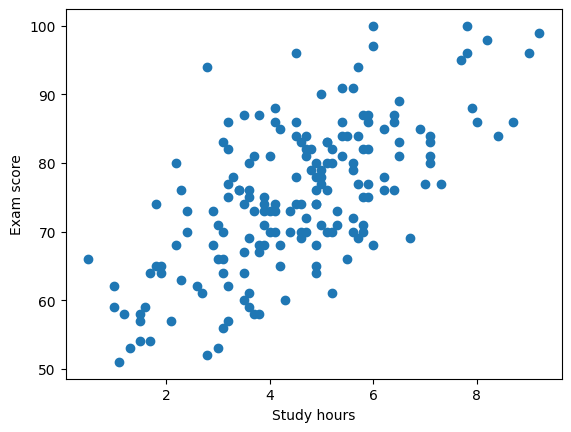

In [16]:
plt.scatter(df["study_hours"], df["exam_score"])
plt.xlabel("Study hours")
plt.ylabel("Exam score")
plt.show()

# **5. Prepare the data**

In [18]:
features = ["study_hours", "attendance_percent", "previous_score", "sleep_hours"]
X = df[features]
y = df["exam_score"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# fill missing inputs with the median of the training rows only (no data leakage)
medians = X_train.median()
X_train = X_train.fillna(medians)
X_test = X_test.fillna(medians)

# **6. Train the model**

In [19]:
model = RandomForestRegressor(random_state=42)
model.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

# **7. Evaluate the model**

In [20]:
predictions = model.predict(X_test)
print("MAE:", mean_absolute_error(y_test, predictions))

MAE: 6.047179487179487


# **8. Make a prediction**

In [21]:
new_student = pd.DataFrame({
    "study_hours": [6],
    "attendance_percent": [90],
    "previous_score": [75],
    "sleep_hours": [8],
})
score = model.predict(new_student)[0]
print("Predicted score:", round(score))

Predicted score: 85
